# Importing Necessary Libraries

In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec

import pickle
import random

import torch
from torch.utils.data import DataLoader

import time
import os

%matplotlib inline

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams["font.family"] = "Century Schoolbook"


In [2]:
def set_seed(seed):
    'Sets the seed'
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    os.environ['PYTHONHASHSEED'] = str(seed)

rng = torch.Generator().manual_seed(0)

device = ('cuda:0' if torch.cuda.is_available() else 'cpu')

# Importing & Scaling Datasets

In [3]:
# download the data from Zenodo using the link below:

#  replace the path used belor with path where you store the data

data = pd.read_excel(r'..\Results_dervs\res_20250404_115952.xlsx')

# states at time t (drop last row to align with next-step targets)
x_t = data.iloc[:-1, :10].reset_index(drop=True)

# inputs at time t
u_t = data.iloc[:-1][['CPL_Prop', 'PPL']].reset_index(drop=True)

# constant Vref at time t
vref = pd.Series(6000.0, index=x_t.index, name='Vref')

# final inputs: [x_t, CPL_Prop_t, PPL_t, Vref]
input_data = pd.concat([x_t, u_t, vref], axis=1)

# targets are next-step states x_{t+1}
output_data = data.iloc[1:, :10].reset_index(drop=True)

In [4]:
X = input_data.values   
y = output_data.values

X_train, X_val_test, y_train, y_val_test = train_test_split(X, y, test_size=0.3, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_val_test, y_val_test, test_size=0.5, random_state=42)

# Scale the dataset using MinMaxScalar
scaler = MinMaxScaler(feature_range=(-1,1))
scaled_train = scaler.fit_transform(X_train)
scaled_test  = scaler.transform(X_test)
scaled_val   = scaler.transform(X_val)
scaled_data  = scaler.transform(X)

scaler_y = MinMaxScaler(feature_range=(-1,1))
scaled_ytrain = scaler_y.fit_transform(y_train)
scaled_ytest  = scaler_y.transform(y_test)
scaled_yval   = scaler_y.transform(y_val)
scaled_ydata  = scaler_y.transform(y)

# ML Dataset Preparation

In [5]:
from Scripts.preprocessing.dataset_preparation import Load_Dataset

prob = Load_Dataset(scaled_train, scaled_test, scaled_val, scaled_ytrain, scaled_ytest, scaled_yval)
train_dataset, test_dataset, val_dataset = prob.load_data()

In [6]:
set_seed(0)
input_features  = X.shape[1]
output_features = y.shape[1]

# Batch size
train_batch_size = 256
val_batch_size   = val_dataset.X.shape[0]

# Initializing the training and validation dataloaders
train_dataloader  = DataLoader(dataset=train_dataset, batch_size=train_batch_size, shuffle = True)
val_dataloader    = DataLoader(dataset=val_dataset, batch_size=val_batch_size, shuffle = True)

# Calculate the MSE weights for each output variable

mse_weights_un = 1 / scaled_ytrain.std(axis=0)**2
mse_weights = (mse_weights_un)**1.5
print(mse_weights)

[5400.70757236    8.01770845    8.18818887   44.58931814   99.39379247
 2408.78265207 2341.87712174   17.86039487   14.86784054   23.49493965]


# MCDHNN Training Module

*The checkpoints are continuously saved. If the cell below is stoped midway, you can still access the training progress 
from the saved checkpoints*

In [7]:
from Scripts.loss_functions.loss_funcs import *

def train_mc_dropout_model(
    model, train_dataloader, val_dataloader,
    num_epochs, learning_rate, lam,
    patience=100, min_lr=5e-5, mse_weights=None,
    checkpoint_path="checkpoints/trial1.pt"
):
    os.makedirs("checkpoints", exist_ok=True)

    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=lam)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=55, gamma=0.95)

    # Resume if checkpoint exists
    if os.path.exists(checkpoint_path):
        checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
        train_loss_list = checkpoint['train_loss_list']
        val_loss_list = checkpoint['val_loss_list']
        best_loss = checkpoint['best_loss']
        start_epoch = checkpoint['epoch'] + 1
        print(f"Resumed training from epoch {start_epoch}, best loss = {best_loss:.6f}")
    else:
        train_loss_list, val_loss_list = [], []
        best_loss = float('inf')
        start_epoch = 0

    counter = 0
    it = len(train_loss_list)
    start_time = time.time()

    for epoch in range(start_epoch, num_epochs):
        model.train()
        train_losses = []

        for X_batch, y_batch in train_dataloader:
            optimizer.zero_grad()

            train_loss = beta_nll_mod_loss(model, X_batch, y_batch, beta=0.5, mse_weights=mse_weights)
            train_losses.append(train_loss.item())

            train_loss.backward()
            optimizer.step()

        train_loss_avg = np.mean(train_losses)

        # Validation
        model.eval()
        val_losses = []
        with torch.no_grad():
            for X_val, y_val in val_dataloader:
                val_loss = beta_nll_mod_loss(model, X_val, y_val, beta=0.5, mse_weights=mse_weights)
                val_losses.append(val_loss.item())

        val_loss_avg = np.mean(val_losses)

        # Early stopping and checkpointing
        if val_loss_avg < best_loss:
            best_loss = val_loss_avg
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print("Early stopping triggered.")
                break

        # Always save latest state
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'best_loss': best_loss,
            'train_loss_list': train_loss_list,
            'val_loss_list': val_loss_list
        }, checkpoint_path)

        scheduler.step()
        for param_group in optimizer.param_groups:
            param_group['lr'] = max(param_group['lr'], min_lr)

        train_loss_list.append(train_loss_avg)
        val_loss_list.append(val_loss_avg)
        it += 1

        print(
            f"Epoch {epoch} - Iter {it} - "
            f"Train Loss: {train_loss_avg:.6f} - Val Loss: {val_loss_avg:.6f}  "
            f"LR: {param_group['lr']:.6f} - Time: {time.time() - start_time:.1f}s"
        )

    return train_loss_list, val_loss_list

In [8]:
set_seed(0)

# Training with Optuna's best parameters
train_batch_size = 100
val_batch_size   = val_dataset.X.shape[0]

#  Epochs, Learning Rate & Regularization
num_epochs       = 2000
learning_rate    = 0.00138
lam              = 6.845e-10

from Scripts.model.MCDHNN_model import MC_DropoutMLP

# Model Initialization
model = MC_DropoutMLP(
    input_features=input_features,
    output_features=output_features,
    layer_sizes=[237, 162, 184, 134, 45],
    dropout_rate=0.05,
    loss_type="heteroscedastic"  # or "mse"
).to(device)

###############################
# Model Training 
###############################
# Uncomment the section for training the model, 
# Skip to the next section for reproducing the results of the trained model

# train_loss_list, val_losss_list = train_mc_dropout_model(
#     model, train_dataloader, val_dataloader,
#     num_epochs, learning_rate, lam,
#     patience=500, min_lr=5e-5,
#     mse_weights=torch.tensor(mse_weights, device=device)
# )


# Save & load the model and checkpoints

In [9]:
# Load the checkpoints for evaluating the training progress

# checkpoint_path="checkpoints/trial.pt"
# checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
# model.load_state_dict(checkpoint['model_state_dict'])

In [10]:
#  Saving the model
# torch.save(model.state_dict(), r'.\Saved_models\model.pth')

# To load the model state dictionary back:
model = MC_DropoutMLP(input_features, output_features, layer_sizes=[237, 162, 184, 134, 45],
                       dropout_rate=0.05, loss_type="heteroscedastic" )
model = model.to(device)
model.load_state_dict(torch.load(r'.\Saved_models\Trained_MCDHNN_model.pth'))

<All keys matched successfully>

# MC Passes Selection Strategy

In [11]:

from Scripts.evaluation.probabilistic_metrics import compute_stochastic_scores
from Scripts.evaluation.model_inference import get_mc_dropout_pred

mc_passes = [10, 50, 100, 200, 300, 400, 500, 600,800, 1000]
# mc_passes = [10]
lower_errs = {}; upper_errs = {}; total_errs = {}; epi_std_all = {}
picp_dict = {}; pinaw_dict = {}; entropy_dict = {}; crps_norm_dict = {}

confidence_levels = [0.95, 0.90]

for mc in mc_passes:
    mean_pred, lb_pred, ub_pred, total_std_pred, epi_pred, ale_pred = get_mc_dropout_pred(model, scaler_y, val_dataset.X, mc_samples=mc, ci=0.95)

    abs_err = np.abs(mean_pred - y_val)          # (samples, outputs)

    # Normalize each output by its mean absolute value
    # so all outputs contribute equally regardless of scale
    norm_factor = np.abs(y_val).mean(axis=0)     # (outputs,)  — per-output scale
    abs_err_norm = abs_err / norm_factor            # (samples, outputs) normalized

    # Now aggregation across outputs is meaningful
    error = abs_err_norm.mean(axis=0).mean()        # scalar — mean across outputs and samples
    error_std = abs_err_norm.std(axis=0).mean()     # scalar — mean of per-output SDs

    lower_bound_error = error - 1.96 * error_std
    upper_bound_error = error + 1.96 * error_std

    # Epistemic uncertainty — normalize by same factor
    epi_norm = epi_pred / norm_factor               # (samples, outputs)
    epi_std_all[mc] = epi_norm.mean(axis=0).mean()  # scalar

    lower_errs[mc] = lower_bound_error
    upper_errs[mc] = upper_bound_error
    total_errs[mc] = error

    # Get probabilistic metrics to show the performance of the model in terms of uncertainty calibration
    picp, piw, pinaw, entropy, crps, crps_norm = compute_stochastic_scores(y_val, mean_pred, total_std_pred, confidence_levels)

    # Only keep the results for CI=0.95 (first column)
    picp = np.array(picp)[:,0]
    pinaw = np.array(pinaw)[:,0]
    entropy = np.array(entropy)
    crps_norm = np.array(crps_norm)

    # Update the dictionaries with the results for this number of MC passes
    picp_dict[mc] = picp.mean()
    pinaw_dict[mc] = pinaw.mean()
    entropy_dict[mc] = entropy.mean()
    crps_norm_dict[mc] = crps_norm.mean()

def relative_percentage_change(total_errs):
    k = list(total_errs.keys())
    for i in range(len(k)-1):
        percent_imp = abs(total_errs[k[i+1]] - total_errs[k[i]]) / total_errs[k[i+1]] * 100
        print(f"Relative percentage change from {k[i]} to {k[i+1]}: {percent_imp:.2f}%")

relative_percentage_change(total_errs)
print('--------------------------------')
relative_percentage_change(epi_std_all)
print('--------------------------------')
relative_percentage_change(picp_dict)
print('--------------------------------')
relative_percentage_change(pinaw_dict)
print('--------------------------------')
relative_percentage_change(entropy_dict)
print('--------------------------------')
relative_percentage_change(crps_norm_dict)       

Relative percentage change from 10 to 50: 13.88%
Relative percentage change from 50 to 100: 2.17%
Relative percentage change from 100 to 200: 1.16%
Relative percentage change from 200 to 300: 0.42%
Relative percentage change from 300 to 400: 0.17%
Relative percentage change from 400 to 500: 0.12%
Relative percentage change from 500 to 600: 0.03%
Relative percentage change from 600 to 800: 0.12%
Relative percentage change from 800 to 1000: 0.04%
--------------------------------
Relative percentage change from 10 to 50: 7.11%
Relative percentage change from 50 to 100: 0.94%
Relative percentage change from 100 to 200: 0.40%
Relative percentage change from 200 to 300: 0.19%
Relative percentage change from 300 to 400: 0.07%
Relative percentage change from 400 to 500: 0.05%
Relative percentage change from 500 to 600: 0.03%
Relative percentage change from 600 to 800: 0.06%
Relative percentage change from 800 to 1000: 0.00%
--------------------------------
Relative percentage change from 10 to

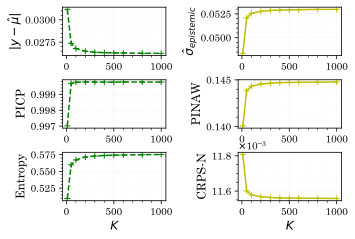

In [12]:
from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((-3, -3))

fig, ax = plt.subplots(3, 2, figsize=(5, 3.5))
fig.subplots_adjust(wspace=.7, hspace=.5)

ax[0,0].plot(total_errs.keys(), total_errs.values(), 'g--+', label='Total Error')
# ax[0,0].set_xlabel('K', fontsize=12)
ax[0,0].set_ylabel(r'$|y-\hat{\mu}|$', fontsize=12)

ax[0,1].plot(epi_std_all.keys(), epi_std_all.values(), 'y-', marker='+', label='Total Error')
# ax[0,1].set_xlabel('Ks', fontsize=12)
ax[0,1].set_ylabel(r'$\hat{\sigma}_{epistemic}$', fontsize=12)

ax[1,0].plot(total_errs.keys(), picp_dict.values(), 'g--+', label='Total Error')
# ax[1,0].set_xlabel('K', fontsize=12)
ax[1,0].set_ylabel('PICP', fontsize=12)

ax[1,1].plot(epi_std_all.keys(), pinaw_dict.values(), 'y-', marker='+', label='Total Error')
# ax[1,1].set_xlabel('Ks', fontsize=12)
ax[1,1].set_ylabel('PINAW', fontsize=12)

ax[2,0].plot(total_errs.keys(), entropy_dict.values(), 'g--+', label='Total Error')
ax[2,0].set_xlabel('$K$', fontsize=12)
ax[2,0].set_ylabel('Entropy', fontsize=12)

ax[2,1].plot(epi_std_all.keys(), crps_norm_dict.values(), 'y-', marker='+', label='Total Error')
ax[2,1].set_xlabel('$K$', fontsize=12)
ax[2,1].set_ylabel('CRPS-N', fontsize=12)
ax[2, 1].yaxis.set_major_formatter(formatter)

for a in ax.flat:
    a.minorticks_on()
    a.grid(which='major', linestyle='-.', alpha=0.2, lw=0.5)
    a.grid(which='minor', linestyle=':', alpha=0.1, lw=0.3)
    # a.set_xscale('log')  

# MCD-HNN Predictions and Uncertainty Decomposition

In [13]:
from Scripts.evaluation.model_inference import get_mc_dropout_pred, get_confidence_bounds

# Make predcitions over the time horizon (train-validation-test splits)
x_input = torch.from_numpy(scaled_data).to(dtype=torch.float32).to(device)
mean_pred_trans, lower_trans, upper_trans, std_pred_trans, epi_std, ale_std = get_mc_dropout_pred(model, scaler_y, x_input, mc_samples=50, ci=0.90)

lower_epi, upper_epi = get_confidence_bounds(0.90, mean_pred_trans, epi_std)
lower_ale, upper_ale = get_confidence_bounds(0.90, mean_pred_trans, ale_std)
lower_tot, upper_tot = get_confidence_bounds(0.90, mean_pred_trans, std_pred_trans)

mlp_train_mean, lb_train, ub_train, mlp_train_std, epi_std_train, ale_std_train = get_mc_dropout_pred(model, scaler_y, train_dataset.X, mc_samples=50, ci=0.90)
mlp_val_mean, lb_val, ub_val, mlp_val_std, epi_std_val, ale_std_val             = get_mc_dropout_pred(model, scaler_y, val_dataset.X, mc_samples=50, ci=0.90)
mlp_test_mean, lb_test, ub_test, mlp_test_std, epi_std_test, ale_std_test       = get_mc_dropout_pred(model, scaler_y, test_dataset.X, mc_samples=50, ci=0.90)


# MCDH-HNN Uncertainty Decompisition

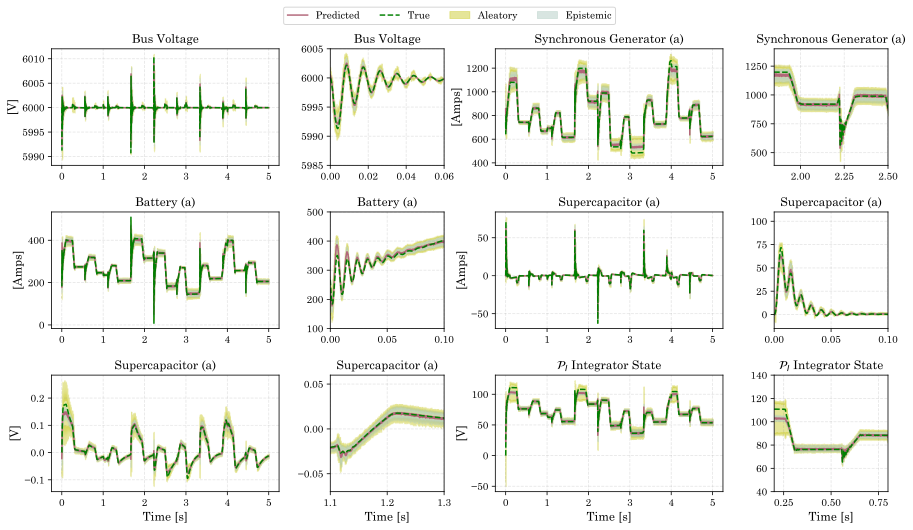

In [14]:
from Scripts.visualization.plot_main_results import plot_predictions_with_uncertainty

plot_predictions_with_uncertainty(mean_pred_trans, lower_tot, upper_tot, lower_epi, upper_epi, y, save_path=None)


# Deterministic Metrics

In [15]:
from Scripts.evaluation.deterministic_metrics import compute_deterministic_scores

det_metrics = compute_deterministic_scores(y_true=y_test, y_pred=mlp_test_mean, n_inputs = X_test.shape[1])
det_metrics

,R²,Adjusted R²,Normalized RMSE,Weighted MAPE
0,0.993938,0.993933,0.000007,0.000002
1,0.991559,0.991552,0.022358,0.012515
2,0.988920,0.988911,0.026324,0.013254
3,0.998435,0.998434,0.010336,0.005509
4,0.998387,0.998386,0.010846,0.004764
5,0.996301,0.996298,0.131573,0.045830
6,0.996361,0.996358,0.139339,0.038473
7,0.989211,0.989202,0.143591,0.060787
8,0.989192,0.989183,0.139358,0.071637
9,0.987798,0.987787,0.029860,0.014555


In [16]:
from Scripts.visualization.plots import residual_plot_with_metrics

# Get the predicted and true trajectories for plotting
pred_cropped = pd.DataFrame(mlp_test_mean)
true_cropped = pd.DataFrame(y_test)

#  Plot the results 
fig = plt.figure(figsize=(12, 5))
outer_gs = gridspec.GridSpec(1,4,figure=fig)

#  Do not use latex for assigning the labels as $$ is used in the function
labels = ['V_{bus}', 'I_{sga}','I_{ba}', 'I_{sca}']

outputs = [0, 1, 3, 5]  # Corresponding to the labels above
for subplot_idx, data_idx in enumerate(outputs):
    y_true = true_cropped.iloc[:, data_idx]
    y_pred = pred_cropped.iloc[:, data_idx]
    label = labels[subplot_idx]

    residual_plot_with_metrics(fig, outer_gs[subplot_idx], y_pred, y_true, label)

plt.tight_layout()

# Probabilistic Metrics

In [17]:
from Scripts.evaluation.probabilistic_metrics import compute_stochastic_scores

confidence_levels        = np.array([0.6, 0.7, 0.8, 0.9, 0.95])
picp, piw, pinaw, entropy, crps, crps_norm = compute_stochastic_scores(y_true=y_test, mean_preds=mlp_test_mean, std_preds=mlp_test_std, confidence_levels=confidence_levels)

picp_score       = pd.DataFrame(picp)
piw_score        = pd.DataFrame(piw)
pinaw_score      = pd.DataFrame(pinaw)
entropy_score    = pd.DataFrame(entropy)
crps_score       = pd.DataFrame(crps)
crps_norm_score  = pd.DataFrame(crps_norm)

stochastic_scores = pd.concat([picp_score, piw_score, pinaw_score, entropy_score, crps_score, crps_norm_score], axis=0)
stochastic_scores.columns = ["60%", "70%","80%","90%","95%"]



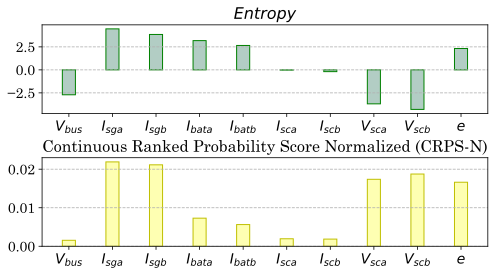

In [18]:
fig, ax = plt.subplots(2, 1, figsize=(8, 4))
fig.subplots_adjust(hspace=0.5)
fig.subplots_adjust(wspace=0.3) 

x_labels = ['$V_{bus}$', '$I_{sga}$', '$I_{sgb}$', '$I_{bata}$', '$I_{batb}$',
            '$I_{sca}$', '$I_{scb}$', '$V_{sca}$', '$V_{scb}$', '$e$' ]
x = np.arange((y_test.shape[1]))
bar_width = 0.3

# Plot each row as a group of bars
ax[0].bar(x , entropy_score.iloc[:,0], width=bar_width, facecolor='#b2cdc4', edgecolor='g')
# ax[0].plot(entropy_score.iloc[:,0], 'b--')
ax[0].set_xticks(x, x_labels, fontsize=14)
ax[0].tick_params(axis='y', labelsize=14)
ax[0].set_title('$Entropy$', fontsize = 16)
ax[0].grid(True, axis='y', which='major', linestyle='--')

ax[1].bar(x , crps_norm_score.iloc[:,-1], width=bar_width, facecolor='#feffb2', edgecolor='y')
# ax[1].plot(crps_norm_score.iloc[:,-1], 'k--')
ax[1].set_xticks(x, x_labels, fontsize=14)
ax[1].tick_params(axis='y', labelsize=14)
ax[1].set_title('Continuous Ranked Probability Score Normalized (CRPS-N)', fontsize = 16)
ax[1].grid(True, axis='y', which='major', linestyle='--')

Text(0.5, 1.0, 'PINAW')

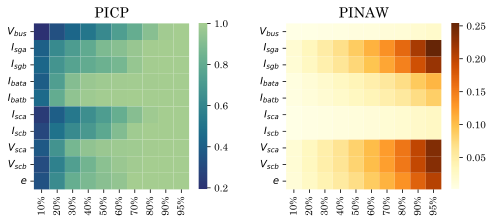

In [19]:
confidence_levels        = np.array([0.1,0.2,0.3,0.4,0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
picp, piw, pinaw, entropy, crps, crps_norm = compute_stochastic_scores(y_true=y_test, mean_preds=mlp_test_mean, std_preds=mlp_test_std, confidence_levels=confidence_levels)

fig, ax = plt.subplots(1, 2, figsize=(8, 3))
fig.subplots_adjust(hspace=0.4)
fig.subplots_adjust(wspace=0.3) 

x_labels = ["10%","20%","30%","40%","50%","60%", "70%", "80%", "90%", "95%"]
y_labels = ['$V_{bus}$', '$I_{sga}$', '$I_{sgb}$', '$I_{bata}$', '$I_{batb}$',
            '$I_{sca}$', '$I_{scb}$', '$V_{sca}$', '$V_{scb}$', '$e$' ]

cmap = sns.color_palette("crest", as_cmap=True).reversed()

sns.heatmap(picp, cmap=cmap, annot=False, xticklabels=x_labels, yticklabels=y_labels, ax=ax[0])
ax[0].set_title('PICP', fontsize=14)

sns.heatmap(pinaw, cmap='YlOrBr', annot=False, xticklabels=x_labels, yticklabels=y_labels, ax=ax[1])
ax[1].set_title('PINAW', fontsize=14)

# Explainable AI 

Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:77: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_mean, X_sample, feature_names=feature_names, plot_type="violin", plot_size=None, show=False)
c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:83: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_epi, X_sample, feature_names=feature_names, plot_type="bar", plot_size=None, show=False)


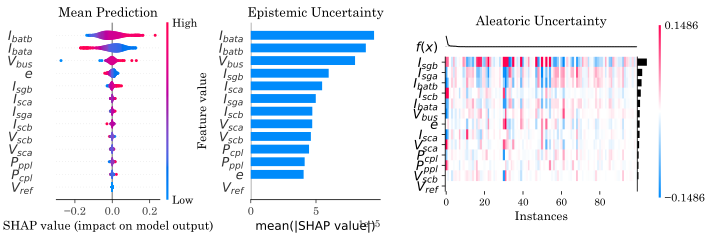

Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:77: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_mean, X_sample, feature_names=feature_names, plot_type="violin", plot_size=None, show=False)
c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:83: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_epi, X_sample, feature_names=feature_names, plot_type="bar", plot_size=None, show=False)


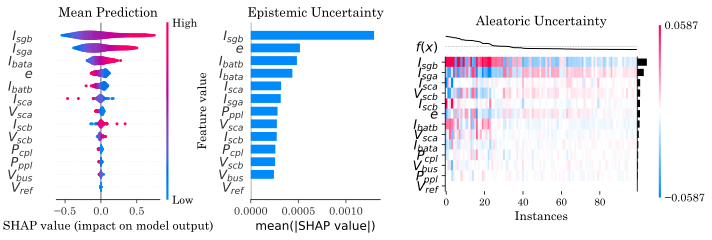

Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:77: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_mean, X_sample, feature_names=feature_names, plot_type="violin", plot_size=None, show=False)
c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:83: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_epi, X_sample, feature_names=feature_names, plot_type="bar", plot_size=None, show=False)


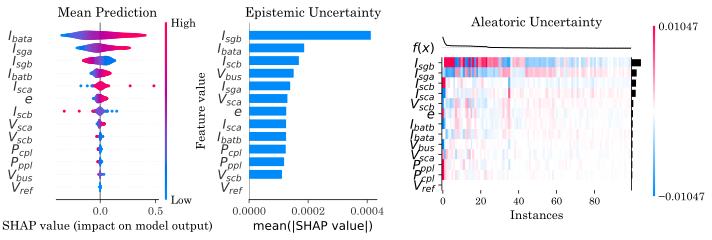

Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
Using 2000 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:77: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_mean, X_sample, feature_names=feature_names, plot_type="violin", plot_size=None, show=False)
c:\Users\nar522\Lehigh University Dropbox\Nazia Raza\DoD Research\Codes\GitHubCodes\Scripts\explainability\shap_evaluation.py:83: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_epi, X_sample, feature_names=feature_names, plot_type="bar", plot_size=None, show=False)


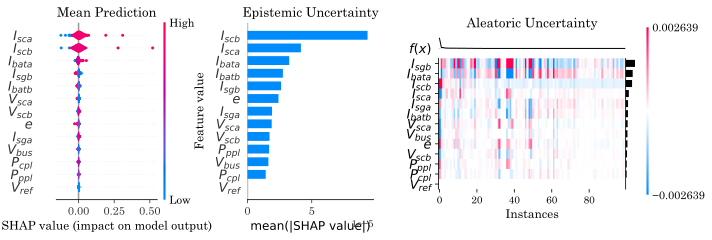

In [20]:
from Scripts.explainability.shap_evaluation import get_shap_values
set_seed(0)
X_background   = train_dataset.X[:2000, :].cpu().numpy()
X_sample       = test_dataset.X[:100, :].cpu().numpy()
indexes = [0,1,3,5]

for output_idx in indexes:
    shap_values_mean, shap_values_epi, shap_values_ale = get_shap_values(model, X_background, X_sample, output_idx, plot=True)